In [29]:
%load_ext autoreload
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch

# personnal
import libraries
import libraries.data_loader as dl
from libraries.gen_masks import get_masks
from libraries.display import display
import libraries.models as model
from libraries.model_parts.cnn import CNN_28x28, TCNN_28x28

from libraries.latent import refresh_save, get_RT_X, load_MU_VAR, get_Asquare, get_KLD, reparametrization_trick
from libraries.tools import mode_to_df 

from IPython.display import clear_output

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
%autoreload 2
json_modes = {
    "VAE": {
        "F": 1,
        "model" : model.VAE,
        "loss" : ["loss", "IMG", "KLD"], 
        "rep": "MNIST"
    }, 
    "VAE-RT":{
        "F": 2,
        "model" : model.VAE,
        "loss" : ["loss", "STRUCT", "DOSE", "KLD"], 
        "rep": "RT-MNIST"
    }, 
    "TCVAE":{
        "F": 1,
        "model" : model.TCVAE,
        "loss" : ["loss", "IMG", "KLD", "COV"], 
        "rep": "MNIST"
    }, 
    "TCVAE-RT": {
        "F": 2,
        "model" : model.TCVAE,
        "loss" : ["loss", "STRUCT", "DOSE", "KLD", "COV"], # TC-COV :  
        "rep": "RT-MNIST"
    },
    "DVAE": {
        "F": 1,
        "model" : model.DVAE,
        "loss" : ["loss", "IMG", "KLD", "CS"]
    },
    "DVAE-RT": {
        "F": 2,
        "model" : model.DVAE,
        "loss" : ["loss", "STRUCT", "DOSE", "KLD", "CS"]
    }
}

mode = "TCVAE-RT"
str_loss_colnames = json_modes[mode]["loss"]

In [104]:
list(json_modes.keys())

['VAE', 'VAE-RT', 'TCVAE', 'TCVAE-RT', 'DVAE', 'DVAE-RT']

In [26]:
modes = list(json_modes.keys())
path = r"Results\\Results 28x28"

df = mode_to_df(modes, path)
df

,path,mode,RT,alpha,beta,gamma,lambda
0,Results\\Results 28x28\VAE\beta_0.2,VAE,0,None,0.2,None,None
1,Results\\Results 28x28\VAE\beta_0.5,VAE,0,None,0.5,None,None
2,Results\\Results 28x28\VAE\beta_1.0,VAE,0,None,1.0,None,None
3,Results\\Results 28x28\VAE-RT\alpha_0.25-beta_0.5,VAE-RT,1,0.25,0.5,None,None
4,Results\\Results 28x28\VAE-RT\alpha_0.25-beta_1.0,VAE-RT,1,0.25,1.0,None,None
5,Results\\Results 28x28\VAE-RT\alpha_0.5-beta_0.2,VAE-RT,1,0.5,0.2,None,None
6,Results\\Results 28x28\VAE-RT\alpha_0.5-beta_0.5,VAE-RT,1,0.5,0.5,None,None
7,Results\\Results 28x28\VAE-RT\alpha_0.5-beta_1.0,VAE-RT,1,0.5,1.0,None,None
8,Results\\Results 28x28\TCVAE\beta_0.2-gamma_1.8,TCVAE,0,None,0.2,1.8,None
9,Results\\Results 28x28\TCVAE\beta_0.5-gamma_1.5,TCVAE,0,None,0.5,1.5,None


# Get latent

In [5]:
path = r"datas/mnist.npz"
keys = ['x_train', 'y_train', 'x_test', 'y_test']

X_train, Y_train, X_val, Y_val = dl.load_datas(path, keys)


X_train = X_train.reshape((60000, 1, 28, 28))
X_val = X_val[:].reshape((10000, 1, 28, 28))


X_train.shape, X_val.shape

((60000, 1, 28, 28), (10000, 1, 28, 28))

In [6]:
path = r"datas/rt-mnist.npz"
keys = ["masks", "mus", "stds"] # 

with np.load(path) as f:
    M, MUS, STDS = [f[k] for k in keys]

M = M.reshape((-1, 1, 28, 28))
M.shape

(60000, 1, 28, 28)

In [37]:
cur_path = df["path"].iloc[0]
for cur_path in df["path"] :
    if "latent.csv" not in os.listdir(cur_path) :
        print(cur_path)
        net_path = os.path.join(cur_path, "model.pt")
        net = torch.load(net_path, weights_only=False)
        
        # get MU VAR
        MU, VAR = load_MU_VAR(net, X_train, M, F = net.F)
        
        # Keep active vectors
        Asquare = get_Asquare(MU, VAR)
        Asquare = Asquare[Asquare[0] >=  0.05]
        idx_kept = Asquare["index"]
        
        # get a drawn Z
        Z = reparametrization_trick(MU[:, idx_kept], VAR[:, idx_kept])
        Z = pd.DataFrame(Z, columns = idx_kept)
        
        # save latent representation
        latent_path = os.path.join(cur_path, "latent.csv")
        Z.to_csv(latent_path, sep = ";", index = False)

In [103]:
a = "Avis : fixed correlation coefficient lesser than -1, probably due to floating point errors.Avis : fixed correlation coefficient lesser than -1, probably due to floating point errors.Avis : fixed correlation coefficient lesser than -1, probably due to floating point errors.Avis : fixed correlation coefficient lesser than -1, probably due to floating point errors.Avis : fixed correlation coefficient greater than 1, probably due to floating point errors.Avis : fixed correlation coefficient greater than 1, probably due to floating point errors.Avis : fixed correlation coefficient greater than 1, probably due to floating point errors.Avis : fixed correlation coefficient greater than 1, probably due to floating point errors.Avis : fixed correlation coefficient greater than 1, probably due to floating point errors.Avis : fixed correlation coefficient greater than 1, probably due to floating point errors.Avis : fixed correlation coefficient lesser than -1, probably due to floating point errors.Avis : fixed correlation coefficient greater than 1, probably due to floating point errors.Avis : fixed correlation coefficient lesser than -1, probably due to floating point errors.Avis : fixed correlation coefficient greater than 1, probably due to floating point errors.Avis : fixed correlation coefficient lesser than -1, probably due to floating point errors.Avis : fixed correlation coefficient lesser than -1, probably due to floating point errors.Avis : fixed correlation coefficient greater than 1, probably due to floating point errors.Avis : fixed correlation coefficient greater than 1, probably due to floating point errors.Avis : fixed correlation coefficient lesser than -1, probably due to floating point errors.Avis : fixed correlation coefficient greater than 1, probably due to floating point errors.Avis : fixed correlation coefficient greater than 1, probably due to floating point errors.Avis : fixed correlation coefficient greater than 1, probably due to floating point errors.Avis : fixed correlation coefficient greater than 1, probably due to floating point errors."
a = a.split(".")
len(a)

24

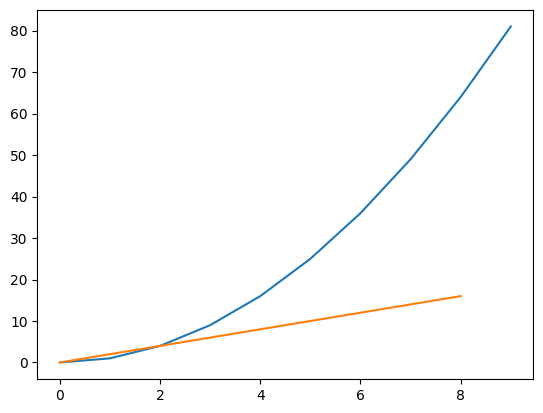

In [53]:
dx = 1
a = np.arange(0, 10, dx)
f = a**2
b = f[1:] -f[:-1] -dx

plt.plot(f)
plt.plot(b)

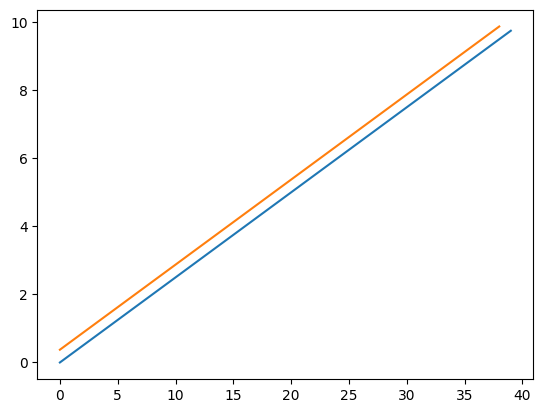

In [97]:
dx = 0.25
a = np.arange(0, 10, dx)
f = a**2
b = f[1:] -f[:-1]


plt.plot(a)
plt.plot(b /(2*dx) +dx)

In [98]:
a

array([0.  , 0.25, 0.5 , 0.75, 1.  , 1.25, 1.5 , 1.75, 2.  , 2.25, 2.5 ,
       2.75, 3.  , 3.25, 3.5 , 3.75, 4.  , 4.25, 4.5 , 4.75, 5.  , 5.25,
       5.5 , 5.75, 6.  , 6.25, 6.5 , 6.75, 7.  , 7.25, 7.5 , 7.75, 8.  ,
       8.25, 8.5 , 8.75, 9.  , 9.25, 9.5 , 9.75])

In [99]:
b *(1/dx)**2  #  = (2k+1)*(1/dx)**2 = 2k*(1/dx)**2 +(1/dx)**2

array([ 1.,  3.,  5.,  7.,  9., 11., 13., 15., 17., 19., 21., 23., 25.,
       27., 29., 31., 33., 35., 37., 39., 41., 43., 45., 47., 49., 51.,
       53., 55., 57., 59., 61., 63., 65., 67., 69., 71., 73., 75., 77.])

In [102]:
1/(1/dx)**2

0.0625